# 5. Chebyshev differentiation matrices

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/05_chebyshev_differentiation_matrices.ipynb)

*Companion to Chapter 6 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

Notebook 4 showed that on a bounded interval the right grid is the **Chebyshev points**,
crowded towards the ends, and that the polynomial through data at those points is an excellent
approximation of a smooth function. Differentiate that polynomial and you have a spectral
method for bounded intervals. This notebook builds the matrix that does it, the single most
reused piece of code in the rest of the course.

You will see:

- a differentiation matrix for **any** set of points, from the barycentric weights
- the closed formula for Chebyshev points, and a trick that keeps it accurate
- convergence for functions of different smoothness
- other intervals, second derivatives, and the effect of rounding errors

**Worked example:** the heat flux at the base of a cooling fin, from temperatures at a few points.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 5.1 The idea, for any set of points

Given values $u_0, \dots, u_N$ at distinct points $x_0, \dots, x_N$:

1. let $P(x)$ be the unique polynomial of degree at most $N$ with $P(x_j) = u_j$;
2. set $w_i = P'(x_i)$.

The map from $\mathbf{u}$ to $\mathbf{w}$ is linear, so it is a matrix: $\mathbf{w} = D\mathbf{u}$.

**By hand.** Write $P$ in the Lagrange form, $P(x) = \sum_j u_j\,\ell_j(x)$, where $\ell_j$ is the
polynomial equal to 1 at $x_j$ and 0 at the other points. Then $D_{ij} = \ell_j'(x_i)$.
With the barycentric weights of notebook 4, $\lambda_j = 1/\prod_{k \ne j}(x_j - x_k)$, this
derivative has a compact form:

$$D_{ij} = \frac{\lambda_j/\lambda_i}{x_i - x_j}\quad (i \ne j),\qquad
D_{ii} = -\sum_{j \ne i} D_{ij} .$$

The diagonal formula says that every row sums to zero. It must: the interpolant of constant
data is a constant, and its derivative is zero.

In [2]:
def diff_matrix(x):
    """Differentiation matrix for polynomial interpolation at the distinct points x."""
    x = np.asarray(x, dtype=float)
    dx = x[:, None] - x[None, :]
    np.fill_diagonal(dx, 1.0)
    weights = 1 / dx.prod(axis=1)                    # barycentric weights λ_j
    D = (weights[None, :] / weights[:, None]) / dx
    np.fill_diagonal(D, 0.0)
    np.fill_diagonal(D, -D.sum(axis=1))
    return D

**Verify** on three equally spaced points $-h, 0, h$. The matrix must reproduce the classic
three-point formulas: one-sided at the ends, centred in the middle.

In [3]:
h = 0.1
D3 = diff_matrix([-h, 0.0, h])
expected = np.array([[-3, 4, -1], [-1, 0, 1], [1, -4, 3]]) / (2 * h)
assert np.allclose(D3, expected)
print(D3 * 2 * h)

[[-3.  4. -1.]
 [-1. -0.  1.]
 [ 1. -4.  3.]]


So finite difference formulas are the special case of a few neighbouring points. A spectral
method uses **all** the points at once. On equally spaced points that would be a disaster
(the Runge phenomenon of notebook 4). On Chebyshev points it works.

## 5.2 The Chebyshev differentiation matrix

The Chebyshev points are $x_j = \cos(j\pi/N)$, $j = 0, \dots, N$. Note the ordering: $x_0 = 1$
and $x_N = -1$, so the points run from **right to left**. This convention is standard, and it
matters whenever you pick out a boundary row.

For these points the barycentric weights are known in closed form: they alternate in sign, and
the two end weights are half the size of the others. Substituting into 5.1 gives

$$D_{ij} = \frac{c_i}{c_j}\,\frac{(-1)^{i+j}}{x_i - x_j}\quad (i \ne j),\qquad
c_0 = c_N = 2,\quad c_j = 1 \text{ otherwise},$$

with the diagonal again fixed by the zero row sums.

The function below keeps the name, the calling convention and the algorithm of `cheb.m` in
Chapter 6 of the book, so that readers of both can move between them.

In [4]:
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

D, x = cheb(4)
print("points:", np.round(x, 4))
print(np.round(D, 4))

points: [ 1.      0.7071  0.     -0.7071 -1.    ]
[[ 5.5    -6.8284  2.     -1.1716  0.5   ]
 [ 1.7071 -0.7071 -1.4142  0.7071 -0.2929]
 [-0.5     1.4142  0.     -1.4142  0.5   ]
 [ 0.2929 -0.7071  1.4142  0.7071 -1.7071]
 [-0.5     1.1716 -2.      6.8284 -5.5   ]]


**Verify** in three ways: against the general construction of 5.1, against the textbook values
of the corner entries, $D_{00} = -D_{NN} = (2N^2+1)/6$, and by differentiating polynomials,
which must be exact up to degree $N$.

In [5]:
N = 12
D, x = cheb(N)
assert np.allclose(D, diff_matrix(x))
assert np.isclose(D[0, 0], (2 * N**2 + 1) / 6) and np.isclose(D[N, N], -(2 * N**2 + 1) / 6)
for degree in range(1, N + 1):
    assert np.abs(D @ x**degree - degree * x ** (degree - 1)).max() < 1e-9
print(f"corner entry D[0,0] = {D[0, 0]:.2f}   its neighbour D[0,1] = {D[0, 1]:.2f}   4N²/π² = {4 * N**2 / np.pi**2:.2f}")
assert abs(abs(D[0, 1]) / (4 * N**2 / np.pi**2) - 1) < 0.01 and np.isclose(np.abs(D).max(), abs(D[0, 1]), rtol=1e-12)

corner entry D[0,0] = 48.17   its neighbour D[0,1] = -58.70   4N²/π² = 58.36


The entries near the corners grow like $N^2$: the corner entry is $(2N^2+1)/6$ and its
neighbour, the largest entry of the matrix, is close to $4N^2/\pi^2$. That is the signature of
the clustered grid: near the ends the spacing is about $\pi^2/(2N^2)$, so derivatives there
divide by very small numbers. Section 5.6 returns to the consequences.

## 5.3 Worked example: heat flux at the base of a fin

**Problem.** The temperature excess along a straight fin with an insulated tip is
$\theta(x) = \dfrac{\cosh m(1-x)}{\cosh m}$ for $0 \le x \le 1$, in dimensionless form. The
quantity of engineering interest is the heat flow into the base, proportional to
$-\theta'(0) = m\tanh m$. Estimate it from the temperatures at $N + 1$ points, for $m = 3$.

The fin occupies $[0, 1]$ and the Chebyshev points live on $[-1, 1]$. A linear change of
variable $x = a + (b-a)(\xi+1)/2$ maps one to the other, and by the chain rule the matrix is
multiplied by $2/(b-a)$.

In [6]:
def scale_cheb(N, a, b):
    """Chebyshev matrix and points mapped from [-1, 1] to [a, b] (x runs from b down to a)."""
    D, x = cheb(N)
    return D * 2 / (b - a), a + (b - a) * (x + 1) / 2

m_fin = 3.0
theta = lambda x: np.cosh(m_fin * (1 - x)) / np.cosh(m_fin)
exact_flux = m_fin * np.tanh(m_fin)

print("  N   Chebyshev error   equispaced 3-point error")
for N in (4, 8, 12, 16):
    D, x = scale_cheb(N, 0.0, 1.0)
    flux_cheb = -(D @ theta(x))[-1]                      # the last point is x = 0, the base
    h = 1 / N                                            # same number of points, equally spaced
    flux_fd = -(-3 * theta(0) + 4 * theta(h) - theta(2 * h)) / (2 * h)
    print(f"{N:3d}   {abs(flux_cheb - exact_flux):12.1e}   {abs(flux_fd - exact_flux):16.1e}")

D, x = scale_cheb(16, 0.0, 1.0)
assert abs(-(D @ theta(x))[-1] - exact_flux) < 1e-10

  N   Chebyshev error   equispaced 3-point error
  4        3.9e-02            3.3e-01
  8        7.0e-06            1.1e-01
 12        1.8e-10            5.2e-02
 16        5.7e-14            3.0e-02


With 17 temperatures the Chebyshev estimate of the wall flux is correct to thirteen digits, where
the one-sided difference formula on an equally spaced grid has two. Wall gradients (heat flux,
wall shear stress, mass-transfer rate) are exactly what engineers want from a computed profile,
and the clustering of Chebyshev points towards the walls is well suited to them.

## 5.4 How fast does it converge?

The answer depends on the smoothness of the function, in the same way as for Fourier methods in
notebook 3. Four test functions on $[-1, 1]$, from rough to perfectly smooth:

| Function | Smoothness | Expected error in the derivative |
| --- | --- | --- |
| $\max(0, x)^3$ | third derivative jumps at $x = 0$ | algebraic, about $N^{-2}$ |
| $\exp\!\big(-1/(1-x^2)\big)$ | infinitely differentiable, not analytic at $\pm1$ | faster than any power of $N$ |
| $1/(1+4x^2)$ | analytic, poles at $x = \pm i/2$ | geometric, $N\rho^{-N}$ |
| $x^8$ | polynomial | exact for $N \ge 8$ |

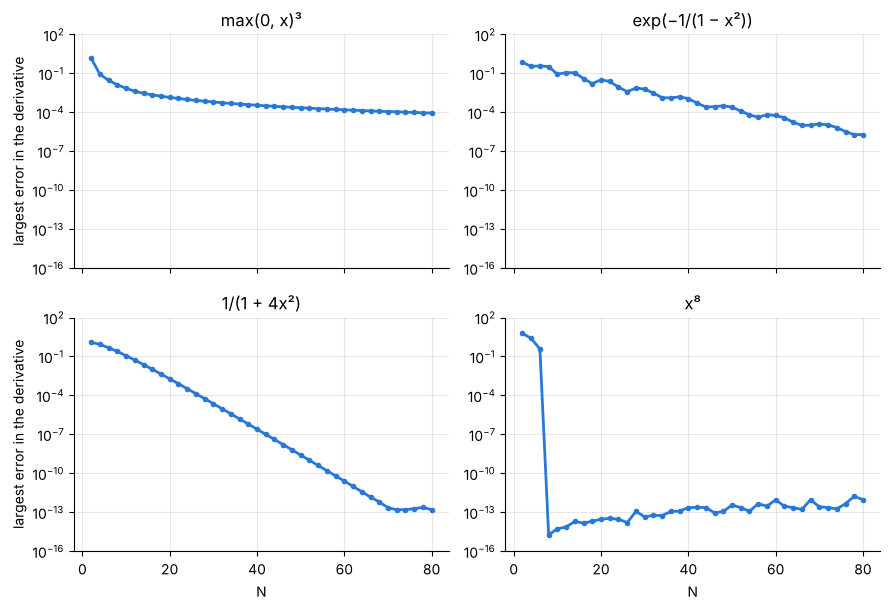

In [7]:
def bump(x):
    inside = np.abs(x) < 1
    safe = np.where(inside, 1 - x**2, 1.0)
    return np.where(inside, np.exp(-1 / safe), 0.0)

def bump_derivative(x):
    inside = np.abs(x) < 1
    safe = np.where(inside, 1 - x**2, 1.0)
    return np.where(inside, -2 * x / safe**2 * np.exp(-1 / safe), 0.0)

tests = {
    "max(0, x)³": (lambda x: np.maximum(0, x) ** 3, lambda x: 3 * np.maximum(0, x) ** 2),
    "exp(−1/(1 − x²))": (bump, bump_derivative),
    "1/(1 + 4x²)": (lambda x: 1 / (1 + 4 * x**2), lambda x: -8 * x / (1 + 4 * x**2) ** 2),
    "x⁸": (lambda x: x**8, lambda x: 8 * x**7),
}

N_values = np.arange(2, 81, 2)
convergence = {}
for name, (f, df) in tests.items():
    convergence[name] = np.array([np.abs(cheb(N)[0] @ f(cheb(N)[1]) - df(cheb(N)[1])).max() for N in N_values])

fig, axes = plt.subplots(2, 2, figsize=(9, 6.2), sharex=True)
for ax, (name, err) in zip(axes.flat, convergence.items()):
    ax.semilogy(N_values, np.maximum(err, 1e-17), "o-", ms=3)
    ax.set(title=name, ylim=(1e-16, 1e2))
for ax in axes[1]:
    ax.set_xlabel("N")
for ax in axes[:, 0]:
    ax.set_ylabel("largest error in the derivative")
fig.tight_layout()

**Verify the two rates that theory predicts exactly.**

For the analytic function the interpolation error falls like $\rho^{-N}$, where $\rho$ is the
sum of the semi-axes of the largest ellipse with foci $\pm1$ inside which the function is
analytic (the Bernstein ellipse of notebook 4). The poles at $\pm i/2$ lie on the ellipse with
semi-minor axis $\tfrac12$ and semi-major axis $\sqrt{1 + \tfrac14}$, so
$\rho = \tfrac12 + \tfrac{\sqrt5}{2} \approx 1.618$, the golden ratio. Differentiation costs one
factor of $N$, so the derivative error behaves like $N\rho^{-N}$, and the fit below divides
that factor out.

In [8]:
analytic = convergence["1/(1 + 4x²)"]
window = (N_values >= 10) & (N_values <= 60)
rho_measured = np.exp(-np.polyfit(N_values[window], np.log(analytic[window] / N_values[window]), 1)[0])
rho_theory = (1 + np.sqrt(5)) / 2
print(f"measured ρ = {rho_measured:.4f}   theory = {rho_theory:.4f}")
assert abs(rho_measured / rho_theory - 1) < 5e-3

rough = convergence["max(0, x)³"]
late = N_values >= 20
algebraic_order = -np.polyfit(np.log(N_values[late]), np.log(rough[late]), 1)[0]
print(f"measured algebraic order for max(0, x)³: {algebraic_order:.2f}")
assert abs(algebraic_order - 2) < 0.2
assert convergence["x⁸"][N_values == 8][0] < 1e-11

measured ρ = 1.6180   theory = 1.6180
measured algebraic order for max(0, x)³: 2.00


The location of a singularity in the **complex** plane, away from the real interval where the
function is used, fixes the convergence rate to four digits. The polynomial is differentiated
exactly as soon as $N$ reaches its degree, and the function with a jump in its third derivative
converges only algebraically, however many points are used.

The practical reading: spectral methods reward smooth problems. A kink in the data, a corner in
the domain or a discontinuous coefficient costs the exponential convergence (notebook 16
collects such cases and what to do about them).

## 5.5 Second derivatives

The second derivative of the interpolant is obtained by applying $D$ twice, so $D^{(2)} = D^2$.

In [9]:
N = 20
D, x = cheb(N)
D2 = D @ D
u = np.exp(x) * np.sin(3 * x)
exact_second = np.exp(x) * (6 * np.cos(3 * x) - 8 * np.sin(3 * x))
print(f"largest error in u'' with N = {N}: {np.abs(D2 @ u - exact_second).max():.1e}")
assert np.abs(D2 @ u - exact_second).max() < 1e-8

largest error in u'' with N = 20: 9.8e-12


## 5.6 Rounding errors: more points is not always better

In exact arithmetic the error of a smooth function like this one keeps falling as $N$ grows. In
floating point the large entries of $D$ multiply the rounding errors already present in the
data. The entries of $D$ reach about $0.4N^2$ and those of $D^2$ about $0.1N^4$, so errors of size $\varepsilon N^2$ and
$\varepsilon N^4$ must be expected, with $\varepsilon \approx 10^{-16}$.

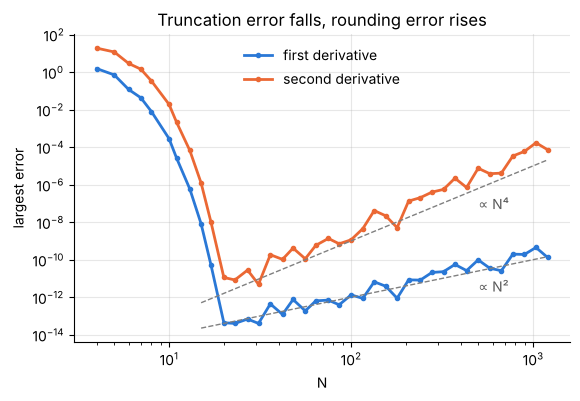

In [10]:
N_wide = np.unique(np.round(np.geomspace(4, 1200, 40)).astype(int))
first, second = [], []
for N in N_wide:
    D, x = cheb(N)
    u = np.exp(x) * np.sin(3 * x)
    first.append(np.abs(D @ u - np.exp(x) * (np.sin(3 * x) + 3 * np.cos(3 * x))).max())
    second.append(np.abs(D @ (D @ u) - np.exp(x) * (6 * np.cos(3 * x) - 8 * np.sin(3 * x))).max())

fig, ax = plt.subplots()
ax.loglog(N_wide, first, "o-", ms=3, label="first derivative")
ax.loglog(N_wide, second, "o-", ms=3, label="second derivative")
ax.loglog(N_wide[8:], 1e-16 * N_wide[8:] ** 2.0, "--", color="0.5", lw=1)
ax.loglog(N_wide[8:], 1e-17 * N_wide[8:] ** 4.0, "--", color="0.5", lw=1)
ax.annotate("∝ N²", xy=(500, 2e-12), color="0.35")
ax.annotate("∝ N⁴", xy=(500, 5e-8), color="0.35")
ax.set(xlabel="N", ylabel="largest error", title="Truncation error falls, rounding error rises")
ax.legend(frameon=False, loc="upper center");

In [11]:
best_first, best_second = N_wide[np.argmin(first)], N_wide[np.argmin(second)]
print(f"most accurate first derivative at N = {best_first} (error {min(first):.0e}); second at N = {best_second} (error {min(second):.0e})")
assert second[-1] > 1e3 * min(second) and first[-1] > 10 * min(first)

most accurate first derivative at N = 23 (error 4e-14); second at N = 31 (error 5e-12)


Each curve has a minimum. To its left the truncation error dominates and falls geometrically;
to its right rounding errors dominate and grow as a power of $N$. The lesson is to use as many
points as the problem needs and no more: with spectral methods that number is usually a few
dozen.

**Why the zero-row-sum diagonal matters.** There is an explicit formula for the diagonal,
$D_{jj} = -x_j/\big(2(1-x_j^2)\big)$ for the interior points. It is mathematically identical
but numerically worse: its rounding errors are unrelated to those of the off-diagonal entries,
so they no longer cancel when the matrix is applied to smooth data.

In [12]:
def cheb_explicit_diagonal(N):
    D, x = cheb(N)
    j = np.arange(1, N)
    D[j, j] = -x[j] / (2 * (1 - x[j] ** 2))
    D[0, 0], D[N, N] = (2 * N**2 + 1) / 6, -(2 * N**2 + 1) / 6
    return D, x

N = 400
D_sum, x = cheb(N)
D_explicit, _ = cheb_explicit_diagonal(N)
u, du = np.exp(x) * np.sin(3 * x), np.exp(x) * (np.sin(3 * x) + 3 * np.cos(3 * x))
error_sum, error_explicit = np.abs(D_sum @ u - du).max(), np.abs(D_explicit @ u - du).max()
print(f"N = {N}:  zero-row-sum diagonal {error_sum:.1e}    explicit diagonal {error_explicit:.1e}")
assert error_explicit > 100 * error_sum

N = 400:  zero-row-sum diagonal 7.2e-12    explicit diagonal 3.9e-08


## Summary

- Differentiating the polynomial interpolant gives a differentiation matrix for any point set;
  finite differences are the few-point special case.
- At Chebyshev points the matrix has a closed form. Fix the diagonal from the zero row sums.
- Remember the ordering: index 0 is $x = +1$ and index $N$ is $x = -1$.
- Convergence is geometric for analytic functions, at a rate set by the nearest complex
  singularity, and only algebraic for functions with a jump in some derivative.
- Rounding errors grow like $\varepsilon N^2$ per derivative. Do not over-resolve.

`cheb(N)` is used unchanged in every later notebook.

## Exercises

1. Compute `cheb(2)` by hand from the formula of 5.2 and check it against the function. Then
   confirm numerically that $D^{N+1}$ is zero to rounding for $N = 5$ (entries of order
   $10^{-11}$), and explain why this must be so.
2. The velocity profile of laminar flow of a power-law fluid in a channel is
   $u(y) = 1 - |y|^{(n+1)/n}$ for $-1 \le y \le 1$. Estimate the wall shear rate $-u'(1)$ with
   `cheb` for $n = 1$, $n = 1/2$ and $n = 0.7$, using $N = 8, 16, 32, 64$. Which cases converge
   spectrally, which do not, and why?
3. Repeat the geometric-rate check of 5.4 for $f(x) = 1/(1 + 25x^2)$. Predict $\rho$ first.
4. Map the Chebyshev points to $[0, 5]$ and differentiate $u(x) = e^{-x}\sin(4x)$. How many
   points are needed for an error below $10^{-8}$ in $u'$? Repeat on $[0, 20]$ and compare.
5. Plot the minimum spacing of the Chebyshev grid against $N$ on logarithmic axes and confirm
   that it scales as $N^{-2}$. What does this imply for the number of points needed to resolve
   a thin boundary layer at a wall, compared with an equally spaced grid?